# 02. Trends
Gies against all campus on retention and graduation, plus the Gies enrollment trend. "All campus" includes Gies. Retention covers the 2021-2025 cohorts and graduation the 2016-2020 cohorts, because a cohort needs six years to finish, so the two series describe different students.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm, linregress

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
rates = pd.read_csv(ROOT / "data/clean/dair_rates.csv")
FIG = ROOT / "dashboard/preview"; FIG.mkdir(parents=True, exist_ok=True)
ACCENT, GRAY = "#D9480F", "#8A8F98"
plt.rcParams.update({"font.family": "DejaVu Sans", "axes.spines.top": False, "axes.spines.right": False})

wide = rates[rates["college_short"].isin(["Gies", "All campus"])].pivot_table(
    index=["metric", "cohort"], columns="college_short", values="rate_pct")
wide["gap_pts"] = (wide["Gies"] - wide["All campus"]).round(2)
print(wide.to_string())

college_short                All campus   Gies  gap_pts
metric               cohort                            
4-year graduation    2016         72.07  84.74    12.67
                     2017         73.49  87.48    13.99
                     2018         73.21  86.12    12.91
                     2019         74.32  87.63    13.31
                     2020         74.21  88.10    13.89
5-year graduation    2016         83.15  90.48     7.33
                     2017         83.17  92.13     8.96
                     2018         83.20  91.01     7.81
                     2019         84.25  91.86     7.61
                     2020         83.27  92.18     8.91
6-year graduation    2016         84.69  91.92     7.23
                     2017         84.89  92.13     7.24
                     2018         85.13  91.96     6.83
                     2019         86.30  92.54     6.24
                     2020         85.04  92.72     7.68
First-year retention 2021         93.32  96.43  

## Is the gap widening or narrowing?
Slope of the Gies-minus-campus gap per cohort. Five points is a thin basis, so this is a description of direction, not a test.

In [2]:
trend = {}
for metric, part in wide.reset_index().groupby("metric"):
    fit = linregress(part["cohort"], part["gap_pts"])
    trend[metric] = {"first_gap": float(part["gap_pts"].iloc[0]), "last_gap": float(part["gap_pts"].iloc[-1]),
                     "largest_gap": float(part["gap_pts"].max()), "smallest_gap": float(part["gap_pts"].min()),
                     "slope_pts_per_cohort": round(float(fit.slope), 2)}
print(pd.DataFrame(trend).T.to_string())

                      first_gap  last_gap  largest_gap  smallest_gap  slope_pts_per_cohort
4-year graduation         12.67     13.89        13.99         12.67                  0.18
5-year graduation          7.33      8.91         8.96          7.33                  0.18
6-year graduation          7.23      7.68         7.68          6.24                 -0.01
First-year retention       3.11      2.45         3.11          0.24                 -0.10


## How Gies ranks among colleges (latest cohort)

In [3]:
latest = {"First-year retention": 2025, "4-year graduation": 2020, "6-year graduation": 2020}
ranks = {}
for metric, cohort in latest.items():
    part = rates[(rates["metric"] == metric) & (rates["cohort"] == cohort) & (rates["college"] != "All campus")]
    ordered = part.sort_values("rate_pct", ascending=False).reset_index(drop=True)
    ranks[metric] = int(ordered.index[ordered["college_short"] == "Gies"][0] + 1)
    print(metric, cohort, "| Gies rank", ranks[metric], "of", len(ordered), "|",
          ", ".join(f"{a} {b:.1f}" for a, b in zip(ordered["college_short"], ordered["rate_pct"])))

First-year retention 2025 | Gies rank 1 of 11 | Gies 97.3, LAS 95.6, ACES 95.2, Grainger 94.7, Media 94.4, Education 94.2, FAA 94.0, DES 93.5, iSchool 92.9, AHS 92.9, SSW 90.5
4-year graduation 2020 | Gies rank 1 of 11 | Gies 88.1, iSchool 87.5, Media 82.2, Education 78.5, LAS 76.5, Grainger 75.5, SSW 74.6, AHS 74.4, ACES 73.7, FAA 69.0, DES 63.1
6-year graduation 2020 | Gies rank 1 of 11 | Gies 92.7, iSchool 92.5, Grainger 89.7, LAS 86.1, FAA 84.9, Media 84.8, AHS 83.5, SSW 83.0, Education 82.0, ACES 81.3, DES 76.7


## Two-proportion z-test, latest retention cohort
DAIR gives counts, so the test can run. Gies is compared with the rest of campus (everyone except Gies) because the two groups must not overlap. The unit is the whole cohort rather than a random sample, so the p-value is a guide to how large the gap is against ordinary year-to-year chance, not a survey margin of error.

In [4]:
ret = rates[(rates["metric"] == "First-year retention") & (rates["cohort"] == 2025)].set_index("college_short")
x1, n1 = ret.loc["Gies", "count"], ret.loc["Gies", "cohort_size"]
x2 = ret.loc["All campus", "count"] - x1; n2 = ret.loc["All campus", "cohort_size"] - n1
p1, p2, pooled = x1 / n1, x2 / n2, (x1 + x2) / (n1 + n2)
se = (pooled * (1 - pooled) * (1 / n1 + 1 / n2)) ** 0.5
z = (p1 - p2) / se
p_value = 2 * norm.sf(abs(z))
se_diff = (p1 * (1 - p1) / n1 + p2 * (1 - p2) / n2) ** 0.5
ztest = {"gies_pct": round(100 * p1, 2), "rest_of_campus_pct": round(100 * p2, 2), "diff_pts": round(100 * (p1 - p2), 2),
         "ci_low": round(100 * (p1 - p2 - 1.96 * se_diff), 2), "ci_high": round(100 * (p1 - p2 + 1.96 * se_diff), 2),
         "z": round(z, 2), "p_value": float(f"{p_value:.2g}"), "n_gies": int(n1), "n_rest": int(n2)}
print(ztest)

{'gies_pct': np.float64(97.33), 'rest_of_campus_pct': np.float64(94.65), 'diff_pts': np.float64(2.68), 'ci_low': np.float64(1.46), 'ci_high': np.float64(3.91), 'z': np.float64(3.27), 'p_value': 0.0011, 'n_gies': 787, 'n_rest': 8408}


## Gies enrollment

In [5]:
path = ROOT / "data/clean/dair_enrollment.csv"
enrollment_note = "not available"
if path.exists():
    enr = pd.read_csv(path)
    gies = enr[enr["college"].str.startswith("Gies")].pivot_table(index="fall_year", columns="level", values="headcount").fillna(0).astype(int)
    print(gies.to_string())
    enrollment_note = gies.iloc[[0, -1]].to_dict()
else:
    print("Enrollment file not built yet")

level      Graduate  Undergraduate
fall_year                         
2016           1093           3102
2017           2050           3105
2018           3073           3140
2019           4142           3115
2020           5244           2989
2021           6666           3165
2022           6321           3117
2023           5790           3112
2024           6132           3197
2025           6311           3329
2026           6443           3652


## Preview chart and saved numbers
A preview of dashboard view 1, used until the Tableau export exists.

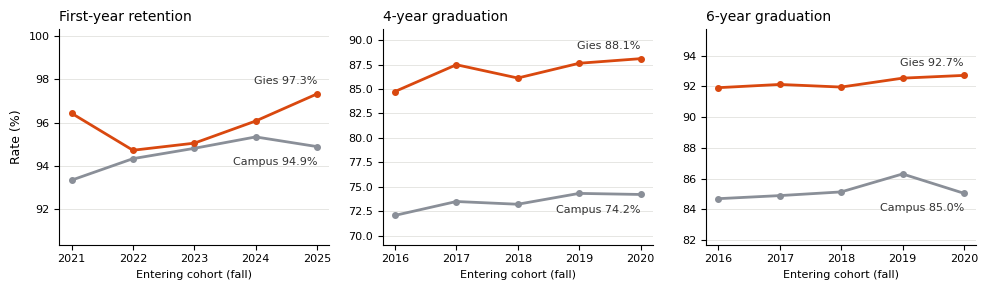

1369

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(10, 3), sharey=False)
for ax, metric in zip(axes, ["First-year retention", "4-year graduation", "6-year graduation"]):
    part = wide.loc[metric]
    ax.plot(part.index, part["All campus"], color=GRAY, lw=2, marker="o", ms=4)
    ax.plot(part.index, part["Gies"], color=ACCENT, lw=2, marker="o", ms=4)
    ax.set_title(metric, loc="left", fontsize=10)
    ax.set_xticks(part.index); ax.tick_params(labelsize=8); ax.grid(axis="y", color="#E6E6E3", lw=.7)
    ax.annotate(f"Gies {part['Gies'].iloc[-1]:.1f}%", (part.index[-1], part["Gies"].iloc[-1]), xytext=(0, 7),
                textcoords="offset points", ha="right", fontsize=8, color="#333")
    ax.annotate(f"Campus {part['All campus'].iloc[-1]:.1f}%", (part.index[-1], part["All campus"].iloc[-1]), xytext=(0, -13),
                textcoords="offset points", ha="right", fontsize=8, color="#333")
    span = part[["Gies", "All campus"]]
    ax.set_ylim(span.min().min() - 3, span.max().max() + 3)
axes[0].set_ylabel("Rate (%)", fontsize=9)
for ax in axes: ax.set_xlabel("Entering cohort (fall)", fontsize=8)
fig.tight_layout(); fig.savefig(FIG / "view1_gies_vs_campus.png", dpi=200); plt.show()

(ROOT / "notebooks/trends_numbers.json").write_text(json.dumps(
    {"trend": trend, "ranks": ranks, "ztest": ztest,
     "latest": {m: wide.loc[m].iloc[-1].to_dict() for m in latest}}, indent=2))